# PostgreSQL Database Exploration


**Prerequisites:**
- The PostgreSQL instance must be running (`make up` in the `scripts/apptainer` directory)
- The server listens on `localhost:5432` with `trust` authentication, which means no password is required.

**Note for HPC clusters:** if the notebook runs on a different node from the one hosting the Postgres instance,
replace `localhost` with the node's hostname (e.g., `node042`) or use an SSH tunnel:
```bash
ssh -N -L 5432:localhost:5432 <node-hosting-postgres>
```


## 1. Library Installation

In [ ]:
%pip install psycopg2-binary sqlalchemy pandas matplotlib seaborn

## 2. Connection Configuration

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

# Connection parameters
DB_HOST = "localhost"
DB_PORT = 5432
DB_USER = "postgres"
DB_PASSWORD = "postgres"

def get_engine(db_name="postgres"):
    """Create a SQLAlchemy engine for the specified database."""
    url = f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{db_name}"
    return create_engine(url)

# Test the connection to the default database
engine = get_engine()
with engine.connect() as conn:
    version = conn.execute(text("SELECT version();")).scalar()
print("Connected")
print(version)

If an error such as: `PANIC: could not locate a valid checkpoint record at 189/7D650F10`
occurs during database startup, it is because Postgres was shut down abruptly. 

On restart, Postgres attempts crash recovery by rereading the WAL from the last checkpoint, but the checkpoint record
referenced by the control file is missing or unreadable (truncated/corrupted WAL).

Without that starting point, recovery is impossible, so the process enters PANIC and the server shuts down. To solve, run the following cell:

In [ ]:
apptainer exec instance://postgres_instance pg_resetwal -D /var/lib/postgresql/data

It uses `pg_resetwal` to recover the existing cluster. It resets the WAL and forces the cluster to restart.

Changes that had not yet been written to disk at the time of the crash are lost, and databases being written to at that moment may be left silently inconsistent.

## 3. List of Available Databases

The query lists the databases created after running `load_dumps.sh` (there should be one for each `.dump` file).

In [2]:
query = """
SELECT d.datname AS database,
       pg_size_pretty(pg_database_size(d.datname)) AS size
FROM pg_database d
WHERE d.datistemplate = false
ORDER BY pg_database_size(d.datname) DESC;
"""

databases = pd.read_sql(query, get_engine())
databases

,database,size
0,trace_e5,709 GB
1,fivedirections_e5,280 GB
2,cadets_e5,275 GB
3,deep_trace_e3,109 GB
4,trace_e3,99 GB
5,clearscope_e5,49 GB
6,theia_e5,36 GB
7,fivedirections_e3,20 GB
8,theia_e3,12 GB
9,cadets_e3,9984 MB


| Dataset | Compressed (GB) | Uncompressed (GB) |
|---|---:|---:|
| TRACE_E5 | 91 | 710 |
| FIVEDIRECTIONS_E5 | 39 | 280 |
| CADETS_E5 | 36 | 276 |
| TRACE_E3 | 11 | 100 |
| CLEARSCOPE_E5 | 6.2 | 49 |
| THEIA_E5 | 5.8 | 36 |
| FIVEDIRECTIONS_E3 | 3.2 | 22 |
| THEIA_E3 | 1.1 | 12 |
| CADETS_E3 | 1.4 | 10 |
| OPTC_H201 | 2 | 9 |
| OPTC_H051 | 1.7 | 7.7 |
| OPTC_H501 | 1.5 | 6.7 |
| CLEARSCOPE_E3 | 0.6 | 4.8 |

## 4. Database Selection and Table Inspection

Set `DB_NAME` to the name of one of the databases listed above to explore the selected database.

In [3]:
DB_NAME = "deep_fivedirections_e3"

In [ ]:
engine = get_engine(DB_NAME)

tables = pd.read_sql("""
SELECT table_name,
       (SELECT COUNT(*) FROM information_schema.columns c
        WHERE c.table_name = t.table_name AND c.table_schema = 'public') AS n_columns
FROM information_schema.tables t
WHERE table_schema = 'public' AND table_type = 'BASE TABLE'
ORDER BY table_name;
""", engine)
print(f"Database '{DB_NAME}': {len(tables)} tables")
tables

### 4.1 Row Count and Size per Table

In [ ]:
engine = get_engine(DB_NAME)

# Table sizes
stats = pd.read_sql("""
SELECT relname AS table_name,
       pg_size_pretty(pg_total_relation_size(relid)) AS size,
       pg_total_relation_size(relid) AS bytes
FROM pg_stat_user_tables
WHERE schemaname = 'public'
ORDER BY pg_total_relation_size(relid) DESC;
""", engine)

# Exact row count for each table (slow on large tables)
stats["row_count"] = [
    pd.read_sql(f'SELECT COUNT(*) AS n FROM public."{t}"', engine)["n"][0]
    for t in stats["table_name"]
]

print(f"Database '{DB_NAME}': {len(stats)} tables, "
      f"{stats['row_count'].sum():,} total rows, "
      f"{stats['bytes'].sum() / 1024**3:.2f} GB")
stats.drop(columns="bytes")

### 4.2 Table Schema (Columns and Types)

In [8]:
TABLE_NAME = "netflow_object"
print(f"Table: {TABLE_NAME}")

schema = pd.read_sql(f"""
SELECT column_name, data_type, is_nullable, column_default
FROM information_schema.columns
WHERE table_schema = 'public' AND table_name = '{TABLE_NAME}'
ORDER BY ordinal_position;
""", engine)
schema

Table: netflow_object


,column_name,data_type,is_nullable,column_default
0,uuid,uuid,NO,None
1,host_id,uuid,YES,None
2,permission,text,YES,None
3,epoch,integer,YES,None
4,properties,jsonb,YES,None
5,local_address,text,YES,None
6,local_port,integer,YES,None
7,remote_address,text,YES,None
8,remote_port,integer,YES,None
9,ip_protocol,integer,YES,None


## 5. Custom Queries

A utility function that accepts a SQL query and returns a pandas `DataFrame`.

In [9]:
def q(sql, db_name=None, limit_preview=True):
    """Execute a query and return a DataFrame.

    Args:
        sql: the SQL query
        db_name: database to query (default: the current DB_NAME)
        limit_preview: if True, print the shape and first rows
    """
    eng = get_engine(db_name) if db_name else engine
    df = pd.read_sql(sql, eng)
    if limit_preview:
        print(f"Result: {df.shape[0]} rows x {df.shape[1]} columns")
    return df

# Example: first 10 rows of the selected table
df = q(f'SELECT * FROM "{TABLE_NAME}" LIMIT 5;')
df

Result: 5 rows x 11 columns


,uuid,host_id,permission,epoch,properties,local_address,local_port,remote_address,remote_port,ip_protocol,file_descriptor
0,00003c26-dde7-4bf1-b8d9-05c41702234b,d2842312-8456-4c8e-add6-e2295d0939d3,None,None,None,128.55.12.67,54085,216.163.248.17,80,6,None
1,0000b108-a1bc-451f-b31a-16366066dc14,d2842312-8456-4c8e-add6-e2295d0939d3,None,None,None,0.0.0.0,52084,,0,6,None
2,0000fe51-7948-4b62-b6f8-54e92cd01c3a,d2842312-8456-4c8e-add6-e2295d0939d3,None,None,None,::,50578,,0,17,None
3,00012849-848e-41d9-b362-07b234ea47f2,d2842312-8456-4c8e-add6-e2295d0939d3,None,None,None,128.55.12.67,53772,158.57.45.15,80,6,None
4,000162cd-921f-44d4-ad31-0184685b4fc5,d2842312-8456-4c8e-add6-e2295d0939d3,None,None,None,0.0.0.0,50305,,0,6,None


In [ ]:
df = q(f'SELECT * FROM "{TABLE_NAME}" WHERE "dst_addr" IS NULL OR "dst_addr" = \'0\' LIMIT 5;')
df

In [10]:
src_ip = "128.55.12.166"   
dst_ip = "166.199.230.185" 
node_uuid = "00000000-0000-0000-0000-000000279530"

TABLE_NAME = "netflow_node_table"

# Query for rows with specific src_addr and dst_addr values
query_src = f"""
SELECT *
FROM "{TABLE_NAME}"
WHERE src_addr = '{src_ip}' AND node_uuid = '{node_uuid}';
"""
df1 = q(query_src)

query_src_dst = f"""
SELECT *
FROM "{TABLE_NAME}"
WHERE src_addr = '{src_ip}' AND dst_addr = '{dst_ip}';
"""
df2 = q(query_src_dst)

Result: 1 rows x 7 columns
Result: 3 rows x 7 columns


In [11]:
df1

,node_uuid,hash_id,src_addr,src_port,dst_addr,dst_port,index_id
0,00000000-0000-0000-0000-000000279530,15597916a58e52380712108ec50aaa080b46b6222d0ab5...,128.55.12.166,45525,166.199.230.185,80,134957


In [12]:
df2

,node_uuid,hash_id,src_addr,src_port,dst_addr,dst_port,index_id
0,00000000-0000-0000-0000-000000279530,15597916a58e52380712108ec50aaa080b46b6222d0ab5...,128.55.12.166,45525,166.199.230.185,80,134957
1,00000000-0000-0000-0000-0000002B1ADE,e596a0139fb0adeb4d2d057ed0fb11b4456d1c253368d5...,128.55.12.166,46316,166.199.230.185,80,138200
2,00000000-0000-0000-0000-0000002974E9,2aea499e72f0bedd224f2d76f07c902af7bf86757a5f83...,128.55.12.166,46162,166.199.230.185,80,137491


In [13]:
node_uuid = "00000000-0000-0000-0000-000001BE5884"
TABLE_NAME = "subject_node_table"

query = f"""
SELECT *
FROM "{TABLE_NAME}"
WHERE node_uuid = '{node_uuid}';
"""
df3 = q(query)
df3

Result: 0 rows x 5 columns


,node_uuid,hash_id,path,cmd,index_id


In [14]:
df1

,node_uuid,hash_id,src_addr,src_port,dst_addr,dst_port,index_id
0,00000000-0000-0000-0000-000000279530,15597916a58e52380712108ec50aaa080b46b6222d0ab5...,128.55.12.166,45525,166.199.230.185,80,134957


In [10]:
df2

,node_uuid,hash_id,src_addr,src_port,dst_addr,dst_port,index_id


In [ ]:
query_zero = f"""
SELECT COUNT(*) AS n_rows_zero_dst_addr
FROM "{TABLE_NAME}"
WHERE dst_addr::integer = 0;
"""

query_nonzero = f"""
SELECT COUNT(*) AS n_rows_nonzero_dst_addr
FROM "{TABLE_NAME}"
WHERE dst_addr::integer != 0;
"""
df = q(query_zero)
df

## 7. Useful Examples for Provenance Datasets

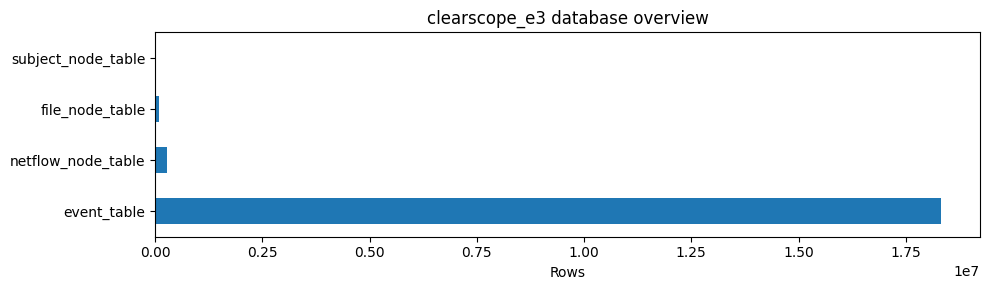

event_table           18316129
netflow_node_table      279694
file_node_table          76938
subject_node_table       12469
Name: rows, dtype: int64

In [13]:
# Overview: row count for each table in the database
overview = {}
for t in tables["table_name"]:
    n = q(f'SELECT COUNT(*) AS n FROM "{t}";', limit_preview=False)["n"].iloc[0]
    overview[t] = n

overview_df = pd.Series(overview, name="rows").sort_values(ascending=False)
overview_df.plot(kind="barh", figsize=(10, max(3, 0.4 * len(overview_df))))
plt.title(f"{DB_NAME} database overview")
plt.xlabel("Rows")
plt.tight_layout()
plt.show()
overview_df

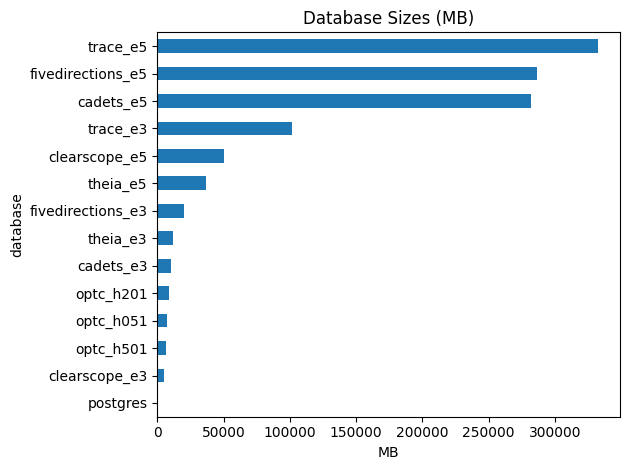

In [14]:
# Compare sizes across all databases
db_sizes = pd.read_sql("""
SELECT datname AS database,
       pg_database_size(datname) / 1024.0 / 1024.0 AS size_mb
FROM pg_database
WHERE datistemplate = false
ORDER BY size_mb DESC;
""", get_engine())

db_sizes.set_index("database")["size_mb"].plot(kind="barh")
plt.title("Database Sizes (MB)")
plt.xlabel("MB")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 8. Restoring a Database

In [ ]:
database_name = "theia_e5" 

apptainer exec instance://postgres_instance \
  psql -U postgres -h localhost -p 5432 \
  -c f"DROP DATABASE IF EXISTS {{database_name}};"

In [ ]:
database_name = "theia_e5" 

apptainer exec instance://postgres_instance \
  psql -U postgres -h localhost -p 5432 \
  -c f"CREATE DATABASE {{database_name}};"

In [ ]:
database_name = "theia_e5" 

apptainer exec instance://postgres_instance \
  pg_restore -U postgres -h localhost -p 5432 \
  --no-owner --no-privileges --exit-on-error \
  -d {{database_name}} /data/{{database_name}}.dump

# 9. Closing Connections

In [12]:
engine.dispose()
print("Connections closed.")

Connections closed.
